<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X4d_complexos_perseguicao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio IV (d): Pepé tem nariz, e o nariz tem uma direção

## Perseguição no plano em notação complexa: câmera no corpo, giroscópio com viés, faróis e o ⊞ multiplicativo

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 4](X4_complexos.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X4_complexos.ipynb)) · **Anterior:** [X4c_complexos_edo.ipynb](X4c_complexos_edo.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X4c_complexos_edo.ipynb))

**A história.** De volta à arena de 40 m do domínio II, com uma mudança em Pepé: agora ele tem **frente**. Ele anda para onde o nariz aponta (como um carrinho: não anda de lado), gira com velocidade limitada, e vê Penélope com uma **câmera presa ao corpo**, que só enxerga o que está à frente, num campo de visão de $\pm70°$.

**Por que isto é o domínio IV.** A câmera mede a posição de Penélope **no referencial de Pepé**: se Pepé está em $p$, com o nariz na direção $q=e^{i\psi}$, e Penélope está em $a$, a câmera vê
$$m=\bar q\,(a-p),$$
o vetor de Pepé até ela, **girado** para as coordenadas do corpo. Em notação complexa, é uma subtração e uma multiplicação. Para usar a medida, Pepé precisa saber a própria orientação $q$. Ele a obtém integrando um **giroscópio**, que tem um **viés**: um erro pequeno e quase constante na velocidade de giro medida, que, integrado, faz a orientação estimada se afastar da verdadeira sem parar (notebook IV(c), seção 6).

**O que este notebook mostra.**
1. Com a orientação **verdadeira**, o filtro de Kalman acompanha Penélope bem, desde que Pepé, quando a perde de vista, gire no lugar para procurá-la.
2. Com a orientação do **giroscópio sem correção**, a estimativa da posição de Penélope gira em torno de Pepé, com erro de metros. Mas Pepé **continua a persegui-la**, porque persegue no referencial do corpo, e esse referencial está certo. É o mapa que está errado, não a perseguição.
3. Com **faróis** em posições conhecidas, um filtro que estima **ao mesmo tempo** a posição de Penélope, a orientação de Pepé e o viés do giroscópio volta a ter a precisão do caso com orientação verdadeira. A orientação é corrigida por **multiplicação**, $\hat q\leftarrow\hat q\,e^{i\delta\psi}$: o $\boxplus$ do domínio IV.
4. Como $U(1)$ é comutativo, corrigir por multiplicação ou somar ao ângulo dá o **mesmo** resultado, até o arredondamento. Nos domínios seguintes, deixará de dar.

**Roteiro**
1. O mundo: a arena, Penélope e o Pepé com nariz
2. Os sensores: câmera no corpo, giroscópio e faróis
3. O filtro: estado, estado de erro e $\boxplus$
4. Orientação verdadeira, e a procura
5. O giroscópio sem correção: o mapa gira, a perseguição não
6. Giroscópio e faróis: o filtro conjunto
7. Tudo junto
8. O que levar deste notebook
9. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

import pandas as pd
from scipy.linalg import expm
N_MC = 20            # simulações de Monte Carlo por configuração (20 → ~15 s no total)

---

## 1. O mundo

**A arena e Penélope** são as do notebook II(d), agora escritas em notação complexa: a posição de Penélope é $a=x+iy$, e as forças (aleatória, de fuga e das paredes) são números complexos. Ela começa em $28+20i$, parada.

**Pepé** está em $p$ (começa em $12+20i$, olhando para leste, $q=1$). A cada passo ele:
- calcula o ângulo, **no referencial do corpo**, até o ponto que quer alcançar: $e=\arg\big(\bar{\hat q}(\text{alvo}-p)\big)$;
- gira com velocidade $\omega=3e$, limitada a 2 rad/s;
- anda para a frente com velocidade proporcional à distância até o alvo, até 2,5 m/s, e mais devagar quanto mais o alvo estiver de lado (proporcional a $\cos e$; se o alvo está atrás, ele só gira);
- atualiza a orientação e a posição: $q\leftarrow q\,e^{i\omega\Delta t}$ e $p\leftarrow p+v\,q\,\Delta t$. A primeira é o RKMK do notebook IV(c); a segunda é "andar $v\Delta t$ na direção $q$".

Pepé conhece a **própria posição** exatamente (um GPS perfeito), para isolar o problema da orientação.

In [2]:
DT, T_FIM, L = 0.05, 60.0, 40.0
SIG_F, TAU_F, F_FUGA, R_FUGA, K_PAREDE = 2.0, 1.5, 3.0, 8.0, 50.0
V_P, W_MAX, GANHO_W, GANHO_V = 2.5, 2.0, 3.0, 1.5
INICIO_A, INICIO_P = 28 + 20j, 12 + 20j

def discretiza(A, B, dt, q=None):
    n, m = A.shape[0], B.shape[1]
    Maug = np.zeros((n + m, n + m)); Maug[:n, :n] = A; Maug[:n, n:] = B
    E = expm(Maug * dt); F, G = E[:n, :n], E[:n, n:]
    if q is None:
        return F, G
    V = np.zeros((2 * n, 2 * n)); V[:n, :n] = -A; V[:n, n:] = B @ np.diag(q) @ B.T; V[n:, n:] = A.T
    W = expm(V * dt); Q = F @ W[:n, n:]
    return F, G, 0.5 * (Q + Q.T)

Z2, I2 = np.zeros((2, 2)), np.eye(2)
F_PEN, G_PEN = discretiza(np.block([[Z2, I2], [Z2, -I2]]), np.vstack([Z2, I2]), DT)
c2v = lambda z: np.array([z.real, z.imag])           # complexo → vetor de ℝ²
v2c = lambda v: v[0] + 1j * v[1]                     # vetor de ℝ² → complexo

def forca_penelope(a, p, f_al):
    d = a - p; r = abs(d)
    fuga = F_FUGA * (d / r if r > 1e-9 else 0) * max(0.0, 1 - r / R_FUGA)
    parede = -K_PAREDE * (min(a.real, 0) + max(a.real - L, 0)) - 1j * K_PAREDE * (min(a.imag, 0) + max(a.imag - L, 0))
    return f_al + fuga + parede

def comando_pepe(p, q_est, alvo):
    e = np.angle(np.conj(q_est) * (alvo - p))           # ângulo até o alvo, no referencial do corpo
    w = np.clip(GANHO_W * e, -W_MAX, W_MAX)
    v = np.clip(GANHO_V * abs(alvo - p) * max(np.cos(e), 0.0), 0.0, V_P)
    return w, v

---

## 2. Os sensores

**A câmera** mede a 10 Hz, com ruído de 0,3 m em cada coordenada do corpo, e só vê o que está a menos de 70° do nariz:
$$\mathbf z=\bar q\,(w-p)+\mathbf v,\qquad\lvert\arg\big(\bar q\,(w-p)\big)\rvert<70°,$$
em que $w$ é o ponto observado: Penélope, ou um farol.

**Os faróis** são quatro lâmpadas fora da arena, em posições conhecidas, uma em cada lado: $20-10i$, $50+20i$, $20+50i$ e $-10+20i$. Separados por 90°, vistos do meio da arena, quase sempre há pelo menos um no campo de visão.

**O giroscópio** mede a velocidade de giro a 20 Hz: $\omega_{\text{medido}}=\omega+b+n$, com ruído de 0,01 rad/s/$\sqrt{\text{Hz}}$ e um viés $b$ que começa em 0,02 rad/s (pouco mais de 1°/s) e passeia devagar, como no notebook IV(c), seção 6.

**O jacobiano da câmera em relação à orientação.** Se a orientação verdadeira é $q=\hat q\,e^{i\delta\psi}$, com $\delta\psi$ pequeno, então
$$\bar q\,(w-p)=e^{-i\delta\psi}\,\underbrace{\bar{\hat q}\,(w-p)}_{\hat m}\approx\hat m-i\,\delta\psi\,\hat m .$$
A derivada da medida em relação ao erro de orientação é $-i\hat m$: o vetor medido girado de $-90°$. Em coordenadas reais, $(\operatorname{Im}\hat m,\ -\operatorname{Re}\hat m)$. A célula confere com diferenças finitas.

In [3]:
FOV, SIG_CAM = np.radians(70), 0.3
FAROIS = np.array([20 - 10j, 50 + 20j, 20 + 50j, -10 + 20j])
B_INICIAL, SIG_GIRO, SIG_VIES = 0.02, 0.01, 5e-4

def camera(q, p, w):
    """Ponto w visto da câmera de Pepé (em p, nariz em q): complexo no referencial do corpo."""
    return np.conj(q) * (w - p)

q_t, p_t, w_t, h = np.exp(0.7j), 10 + 15j, 22 + 31j, 1e-7
m_t = camera(q_t, p_t, w_t)
num = (c2v(camera(q_t * np.exp(1j * h), p_t, w_t)) - c2v(camera(q_t * np.exp(-1j * h), p_t, w_t))) / (2 * h)
confere("∂m/∂δψ = −i m̂, isto é, (Im m̂, −Re m̂)", num, [m_t.imag, -m_t.real], tol=1e-7)
confere("girar e transladar preserva a distância: |m| = |w − p|", abs(m_t), abs(w_t - p_t), tol=1e-14)

OK   ∂m/∂δψ = −i m̂, isto é, (Im m̂, −Re m̂):  diferença máxima = 8.92e-09
OK   girar e transladar preserva a distância: |m| = |w − p|:  diferença máxima = 0.00e+00


---

## 3. O filtro: estado, estado de erro e $\boxplus$

**O estado.** Penélope: posição e velocidade, $(a_x,a_y,v_x,v_y)$, com o modelo de velocidade quase constante dos notebooks II(c) e II(d). Pepé: a orientação $\hat q$ (um complexo unitário) e o viés do giroscópio $\hat b$.

**O estado de erro.** A covariância não pode ser de $\hat q$ (um complexo unitário não é um vetor). Ela é do vetor de seis números
$$\delta\mathbf x=(\delta a_x,\delta a_y,\delta v_x,\delta v_y,\ \delta\psi,\ \delta b),$$
em que $\delta\psi$ é o erro de orientação definido por $q=\hat q\,e^{i\delta\psi}$ (notebook IV(c), seção 6). As quatro primeiras componentes são as de Penélope, e o erro delas é uma diferença comum.

**Predição.** Penélope: $\hat{\mathbf x}\leftarrow\mathbf F\hat{\mathbf x}$. Orientação: $\hat q\leftarrow\hat q\,e^{i(\omega_{\text{medido}}-\hat b)\Delta t}$. Covariância: $\mathbf P\leftarrow\mathbf F_6\mathbf P\mathbf F_6^\top+\mathbf Q_6$, com os blocos dos notebooks II(c) e IV(c).

**Correção.** Cada medida da câmera dá $\delta\hat{\mathbf x}=\mathbf K(\mathbf z-\hat m)$, aplicado assim:
$$\hat a\leftarrow\hat a+\delta\hat a,\quad\hat v\leftarrow\hat v+\delta\hat v,\quad\hat b\leftarrow\hat b+\delta\hat b,\quad\boxed{\hat q\leftarrow\hat q\,e^{i\,\delta\hat\psi}}.$$
A última é o $\boxplus$ multiplicativo do domínio IV. Depois de aplicada, o erro de orientação volta a ser zero (a correção já está em $\hat q$), e o filtro segue.

**Três variantes**, escolhidas por `cfg["orientacao"]`:
- `"verdadeira"`: o filtro usa a orientação verdadeira (só as quatro primeiras componentes);
- `"giroscopio"`: o filtro usa a orientação integrada do giroscópio, **sem** estimar o erro (também só quatro componentes);
- `"conjunto"`: o filtro completo de seis componentes, com os faróis. A opção `"aditivo"` guarda a orientação como **ângulo** e corrige somando, $\hat\psi\leftarrow\hat\psi+\delta\hat\psi$, para comparar.

In [4]:
Q_INT = 1.0
F_CV, _, Q_CV = discretiza(np.block([[Z2, I2], [Z2, Z2]]), np.vstack([Z2, I2]), DT, [Q_INT, Q_INT])
F6 = np.eye(6); F6[:4, :4] = F_CV; F6[4, 5] = -DT
_, _, Q_or = discretiza(np.array([[0.0, -1.0], [0.0, 0.0]]), np.eye(2), DT, [SIG_GIRO**2, SIG_VIES**2])
Q6 = np.zeros((6, 6)); Q6[:4, :4] = Q_CV; Q6[4:, 4:] = Q_or

def simula(cfg, seed):
    rng = np.random.default_rng(seed)
    a, va, f_al = INICIO_A, 0j, 0j
    p, q, b = INICIO_P, 1 + 0j, B_INICIAL
    x = np.r_[c2v(INICIO_A + 3 * (rng.standard_normal() + 1j * rng.standard_normal())), 0.0, 0.0]
    P = np.diag([9.0, 9.0, 4.0, 4.0, 1e-6, 0.05**2])
    q_est, psi_est, b_est = 1 + 0j, 0.0, 0.0
    conjunto = cfg["orientacao"] == "conjunto"
    reg = {k: [] for k in ["t", "a", "p", "a_est", "erro_orient", "visivel"]}
    for k in range(int(T_FIM / DT)):
        # o mundo: Penélope
        f_al = f_al - f_al / TAU_F * DT + SIG_F * np.sqrt(2 * DT / TAU_F) * (rng.standard_normal() + 1j * rng.standard_normal())
        y = F_PEN @ np.r_[c2v(a), c2v(va)] + G_PEN @ c2v(forca_penelope(a, p, f_al))
        a, va = v2c(y[:2]), v2c(y[2:])
        # Pepé decide com a estimativa; se perdeu Penélope de vista, gira no lugar procurando
        alvo = v2c(x[:2]) + cfg.get("tau", 0.0) * v2c(x[2:4])
        w_cmd, v_cmd = comando_pepe(p, q_est, alvo)
        if cfg.get("procura", True) and np.trace(P[:2, :2]) > 16.0:
            w_cmd, v_cmd = W_MAX, 0.0
        q = q * np.exp(1j * w_cmd * DT)
        p = p + v_cmd * q * DT
        p = complex(np.clip(p.real, 0, L), np.clip(p.imag, 0, L))
        b += SIG_VIES * np.sqrt(DT) * rng.standard_normal()
        w_medido = w_cmd + b + SIG_GIRO / np.sqrt(DT) * rng.standard_normal()
        # predição
        if cfg["orientacao"] == "verdadeira":
            q_est = q
        elif cfg.get("aditivo", False):
            psi_est += (w_medido - b_est) * DT; q_est = np.exp(1j * psi_est)
        else:
            q_est = q_est * np.exp(1j * (w_medido - b_est) * DT)
        x = F_CV @ x
        if conjunto:
            P = F6 @ P @ F6.T + Q6
        else:
            P[:4, :4] = F_CV @ P[:4, :4] @ F_CV.T + Q_CV
        # correção: câmera a 10 Hz
        if k % 2 == 1:
            vistos = [("Penélope", a)] if abs(np.angle(camera(q, p, a))) < FOV else []
            if conjunto:
                vistos += [("farol", f) for f in FAROIS if abs(np.angle(camera(q, p, f))) < FOV]
            for tipo, w in vistos:
                z = c2v(camera(q, p, w)) + SIG_CAM * rng.standard_normal(2)
                w_est = v2c(x[:2]) if tipo == "Penélope" else w
                m_est = camera(q_est, p, w_est)
                H = np.zeros((2, 6))
                if tipo == "Penélope":
                    H[:, :2] = [[q_est.real, q_est.imag], [-q_est.imag, q_est.real]]      # ∂(q̄ a)/∂a: girar por q̄
                H[:, 4] = [m_est.imag, -m_est.real]                                     # ∂m/∂δψ = −i m̂
                n = 6 if conjunto else 4
                if not conjunto and tipo != "Penélope":
                    continue
                Hn, Pn = H[:, :n], P[:n, :n]
                S = Hn @ Pn @ Hn.T + SIG_CAM**2 * I2
                K = np.linalg.solve(S, Hn @ Pn).T
                dx = K @ (z - c2v(m_est))
                x = x + dx[:4]
                P[:n, :n] = Pn - K @ S @ K.T; P = 0.5 * (P + P.T)
                if conjunto:
                    b_est += dx[5]
                    if cfg.get("aditivo", False):
                        psi_est += dx[4]; q_est = np.exp(1j * psi_est)        # ⊞ aditivo, no ângulo
                    else:
                        q_est = q_est * np.exp(1j * dx[4])                     # ⊞ multiplicativo
        for nome, val in zip(reg, [(k + 1) * DT, a, p, v2c(x[:2]), abs(np.angle(np.conj(q_est) * q)), abs(np.angle(camera(q, p, a))) < FOV]):
            reg[nome].append(val)
    return {k: np.array(v) for k, v in reg.items()}

def metricas(h):
    e = np.abs(h["a"] - h["a_est"]); d = np.abs(h["a"] - h["p"]); k0 = int(5 / DT)
    return {"perdeu o rastro": bool((e[-int(10 / DT):] > 5).mean() > 0.9),
            "erro mediano (m)": np.median(e[k0:]),
            "tempo com erro > 5 m": np.mean(e[k0:] > 5),
            "erro de orientação (graus)": np.degrees(np.median(h["erro_orient"][k0:])),
            "tempo com ela à vista": np.mean(h["visivel"][k0:]),
            "tempo perto dela (< 1 m)": np.mean(d[k0:] < 1.0),
            "encontros": int(np.sum((d[1:] < 0.5) & (d[:-1] >= 0.5)))}

def monte_carlo(configs, n=N_MC):
    tab = {}
    for nome, cfg in configs.items():
        d = pd.DataFrame([metricas(simula(cfg, 100 + r)) for r in range(n)])
        tab[nome] = {"perdeu o rastro": f"{d['perdeu o rastro'].sum()} de {n}",
                     **{k: d[k].median() for k in d.columns if k != "perdeu o rastro"}}
    return pd.DataFrame(tab).T

def desenha(h, titulo, ax):
    ax.plot(h["a"].real, h["a"].imag, "k", lw=1.2, label="Penélope (verdade)")
    ax.plot(h["p"].real, h["p"].imag, color="tab:purple", lw=1.0, label="Pepé")
    ax.plot(h["a_est"].real, h["a_est"].imag, color="tab:orange", lw=0.8, alpha=.8, label="estimativa de Pepé")
    ax.add_patch(plt.Rectangle((0, 0), L, L, fill=False, lw=2))
    ax.plot(FAROIS.real, FAROIS.imag, "y*", ms=14, mec="k", label="faróis")
    ax.set_xlim(-14, 54); ax.set_ylim(-14, 54); ax.set_aspect("equal"); ax.set_title(titulo, fontsize=10)

---

## 4. Orientação verdadeira, e a procura

O primeiro teste usa a orientação verdadeira: a câmera é então um sensor linear em $a$ (uma rotação conhecida), e o filtro é o de Kalman. A tabela compara Pepé com e sem a regra de **procura**: quando a incerteza da posição de Penélope fica grande (o traço da covariância passa de 16 m², isto é, um desvio de uns 3 m em cada eixo), ele para e gira no lugar até reencontrá-la.

In [5]:
tab_verdade = monte_carlo({"orientação verdadeira, sem procura": {"orientacao": "verdadeira", "procura": False},
                           "orientação verdadeira, com procura": {"orientacao": "verdadeira"}})
tab_verdade.round(3)

,perdeu o rastro,erro mediano (m),tempo com erro > 5 m,erro de orientação (graus),tempo com ela à vista,tempo perto dela (< 1 m),encontros
"orientação verdadeira, sem procura",6 de 20,0.258251,0.0,0.0,0.979091,0.029091,1.0
"orientação verdadeira, com procura",0 de 20,0.245135,0.0,0.0,0.976364,0.053182,1.0


**Leitura.** Sem a procura, Pepé perde Penélope em 6 das 20 simulações, embora o erro mediano seja o mesmo: quando ela sai do campo de visão (ao passar por ele, ou quando ele está contra uma parede), o filtro só prediz, a estimativa segue em linha reta com a última velocidade estimada, e Pepé persegue um fantasma que nunca volta a entrar na câmera. Com a procura, nenhuma perda, e Pepé passa quase o dobro do tempo perto dela. O erro mediano, uns 25 cm, fica abaixo do ruído da câmera (30 cm): o filtro combina muitas medidas.

A partir daqui, todas as configurações usam a procura.

---

## 5. O giroscópio sem correção: o mapa gira, a perseguição não

Agora Pepé usa a orientação integrada do giroscópio, com o viés de 0,02 rad/s, e não tem como corrigi-la.

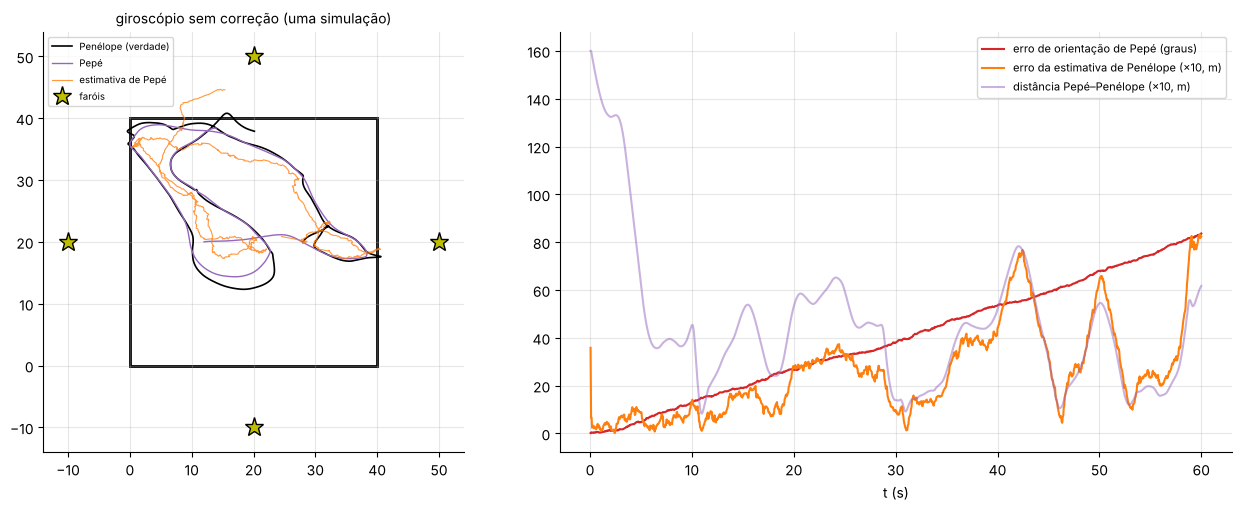

,perdeu o rastro,erro mediano (m),tempo com erro > 5 m,erro de orientação (graus),tempo com ela à vista,tempo perto dela (< 1 m),encontros
giroscópio sem correção,0 de 20,2.103674,0.130455,36.124708,0.935,0.060909,1.0


In [6]:
h = simula({"orientacao": "giroscopio"}, 100)
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1, 1.3]})
desenha(h, "giroscópio sem correção (uma simulação)", ax[0]); ax[0].legend(fontsize=7, loc="upper left")
ax[1].plot(h["t"], np.degrees(h["erro_orient"]), color="tab:red", label="erro de orientação de Pepé (graus)")
ax[1].plot(h["t"], 10 * np.abs(h["a"] - h["a_est"]), color="tab:orange", label="erro da estimativa de Penélope (×10, m)")
ax[1].plot(h["t"], 10 * np.abs(h["a"] - h["p"]), color="tab:purple", alpha=.5, label="distância Pepé–Penélope (×10, m)")
ax[1].set_xlabel("t (s)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

tab_giro = monte_carlo({"giroscópio sem correção": {"orientacao": "giroscopio"}})
tab_giro.round(3)

**Leitura.**
- O erro de orientação cresce **linearmente**, como previsto no notebook IV(c): o viés de 0,02 rad/s integrado dá mais de 80° no fim de um minuto (36° na mediana do tempo e das simulações).
- O erro da estimativa de Penélope acompanha a **distância** entre os dois: a estimativa está certa no referencial de Pepé, e errada só porque esse referencial está girado. Um ponto a distância $r$, girado de $\delta\psi$ em torno de Pepé, se desloca $2r\sin(\delta\psi/2)$: por volta de 42 s, com Pepé a 7,7 m e um erro de orientação de 55°, isso dá 7,1 m, e o gráfico mostra uns 7,6 m. O erro mediano no Monte Carlo é de 2,1 m, com 13% do tempo acima de 5 m.
- E, no entanto, Pepé **não perde** Penélope em nenhuma simulação, e passa tanto tempo perto dela quanto com a orientação verdadeira (6% contra 5%). A explicação está na regra de perseguição: Pepé calcula o ângulo até o alvo com a **mesma** orientação errada com que construiu a estimativa, e os dois erros se cancelam. No referencial do corpo, tudo está certo. Só o **mapa** (onde Penélope está na arena) está errado.

---

## 6. Giroscópio e faróis: o filtro conjunto

O filtro conjunto vê os faróis e Penélope com a mesma câmera, e estima, além de Penélope, o erro de orientação e o viés. A primeira célula confere a afirmação 4 da introdução: com a mesma semente, o filtro com $\boxplus$ multiplicativo ($\hat q\leftarrow\hat q\,e^{i\delta\psi}$) e o filtro aditivo ($\hat\psi\leftarrow\hat\psi+\delta\psi$) dão as mesmas trajetórias, até o arredondamento.

OK   ⊞ multiplicativo = ⊞ aditivo (posição estimada de Penélope, 60 s):  diferença máxima = 3.16e-11
OK   ⊞ multiplicativo = ⊞ aditivo (erro de orientação):  diferença máxima = 1.45e-13


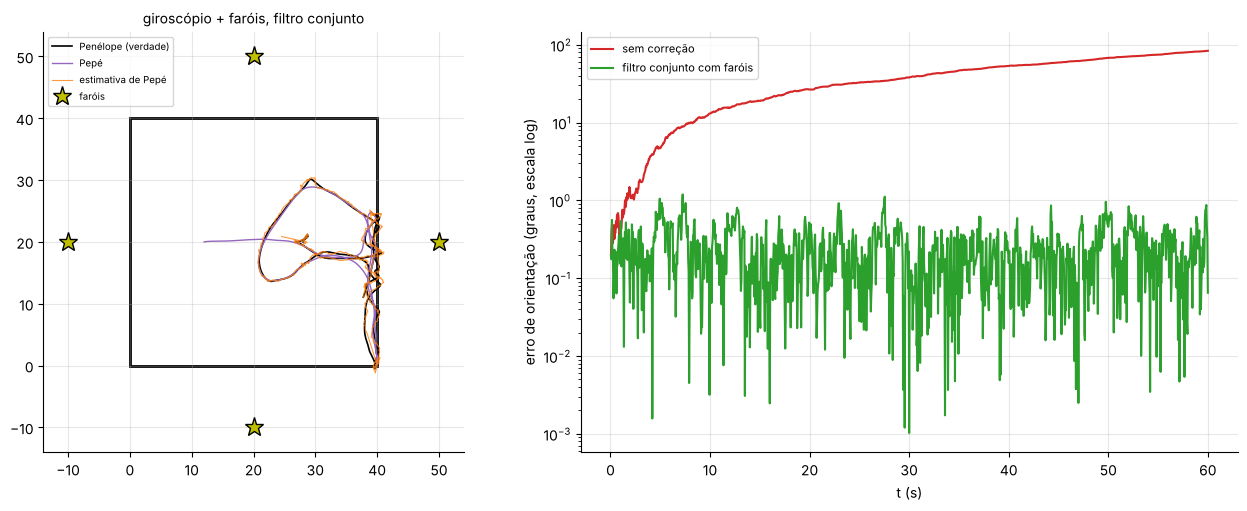

,perdeu o rastro,erro mediano (m),tempo com erro > 5 m,erro de orientação (graus),tempo com ela à vista,tempo perto dela (< 1 m),encontros
"giroscópio + faróis, filtro conjunto",0 de 20,0.251237,0.010455,0.20044,0.943182,0.054091,1.0
"filtro conjunto, mira à frente (τ = 0,8 s)",0 de 20,0.278295,0.052727,0.203896,0.880909,0.07,2.0


In [7]:
h_mult = simula({"orientacao": "conjunto"}, 100)
h_adit = simula({"orientacao": "conjunto", "aditivo": True}, 100)
confere("⊞ multiplicativo = ⊞ aditivo (posição estimada de Penélope, 60 s)", h_mult["a_est"], h_adit["a_est"], tol=1e-8)
confere("⊞ multiplicativo = ⊞ aditivo (erro de orientação)", h_mult["erro_orient"], h_adit["erro_orient"], tol=1e-10)

fig, ax = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1, 1.3]})
desenha(h_mult, "giroscópio + faróis, filtro conjunto", ax[0]); ax[0].legend(fontsize=7, loc="upper left")
h_giro = simula({"orientacao": "giroscopio"}, 100)
ax[1].semilogy(h_giro["t"], np.degrees(h_giro["erro_orient"]) + 1e-3, color="tab:red", label="sem correção")
ax[1].semilogy(h_mult["t"], np.degrees(h_mult["erro_orient"]) + 1e-3, color="tab:green", label="filtro conjunto com faróis")
ax[1].set_xlabel("t (s)"); ax[1].set_ylabel("erro de orientação (graus, escala log)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

tab_conj = monte_carlo({"giroscópio + faróis, filtro conjunto": {"orientacao": "conjunto"},
                        "filtro conjunto, mira à frente (τ = 0,8 s)": {"orientacao": "conjunto", "tau": 0.8}})
tab_conj.round(3)

**Leitura.** Os dois filtros, multiplicativo e aditivo, coincidem até $10^{-11}$ m, como esperado de um grupo comutativo. Com os faróis, o erro de orientação fica em torno de 0,2° (o gráfico mostra que ele nunca passa de pouco mais de 1°, contra os mais de 80° sem correção), e a estimativa de Penélope volta ao nível do caso com orientação verdadeira, uns 25 cm. O viés, que nenhum sensor mede, é descoberto porque faz a orientação derivar, e a deriva aparece nos faróis.

Mirar à frente ($\tau=0{,}8$ s), que ajudava nos domínios anteriores, aqui **atrapalha** um pouco: Pepé aponta o nariz para onde ela vai estar, a câmera deixa de ter Penélope no centro, e o tempo com ela à vista cai de 94% para 88%. Um perseguidor com sensor direcional tem de equilibrar apontar para onde ela está (para ver) e para onde ela vai (para alcançar).

---

## 7. Tudo junto

In [8]:
pd.concat([tab_verdade, tab_giro, tab_conj]).round(3)

,perdeu o rastro,erro mediano (m),tempo com erro > 5 m,erro de orientação (graus),tempo com ela à vista,tempo perto dela (< 1 m),encontros
"orientação verdadeira, sem procura",6 de 20,0.258251,0.0,0.0,0.979091,0.029091,1.0
"orientação verdadeira, com procura",0 de 20,0.245135,0.0,0.0,0.976364,0.053182,1.0
giroscópio sem correção,0 de 20,2.103674,0.130455,36.124708,0.935,0.060909,1.0
"giroscópio + faróis, filtro conjunto",0 de 20,0.251237,0.010455,0.20044,0.943182,0.054091,1.0
"filtro conjunto, mira à frente (τ = 0,8 s)",0 de 20,0.278295,0.052727,0.203896,0.880909,0.07,2.0


**Leitura.** Ninguém perdeu Penélope, exceto o Pepé sem procura. O que a tabela separa é a qualidade do **mapa**: com a orientação verdadeira ou com os faróis, o erro é de uns 25 cm; com o giroscópio sozinho, de 2 m, crescendo com o tempo. E a perseguição, curiosamente, não depende do mapa: os três Pepés com procura passam entre 5% e 6% do tempo a menos de 1 m dela. Se o objetivo fosse outro (avisar um colega de onde Penélope está, ou desenhar o caminho dela na arena), só os faróis serviriam.

---

## 8. O que levar deste notebook

1. **Em notação complexa, mudar de referencial é multiplicar.** A câmera no corpo é $\bar q(a-p)$; o jacobiano em relação à orientação é $-i\hat m$; a predição da orientação é $\hat q\,e^{i\omega\Delta t}$; a correção é $\hat q\,e^{i\delta\psi}$. Nenhum seno, nenhum cosseno escrito à mão.
2. **Estimar o que não se mede diretamente.** O viés do giroscópio não aparece em nenhuma medida; ele é estimado porque faz a orientação derivar, e a deriva aparece nos faróis. O filtro conjunto descobre o viés por consequência.
3. **O referencial certo para a tarefa.** Para perseguir, basta o referencial do corpo; para ter um mapa (onde Penélope está na arena), é preciso a orientação. Um erro de orientação estraga o mapa e preserva a perseguição.
4. **Sensores direcionais pedem comportamento ativo.** Com campo de visão limitado, a regra simples de girar no lugar para procurar evitou todas as perdas.
5. **Multiplicativo ou aditivo, aqui tanto faz.** $U(1)$ é comutativo, e corrigir $\hat q$ por $e^{i\delta\psi}$ é o mesmo que somar $\delta\psi$ ao ângulo. No domínio V (posição e orientação juntas) e no VI (rotações no espaço), a ordem da composição importa, e só a forma multiplicativa é correta.

**Próximo domínio:** os números dual-complexos. Juntando $i$ (rotação) e $\varepsilon$ (translação), um único número descreve a **pose** de um objeto no plano: onde ele está e para onde aponta. É Pepé inteiro, posição e nariz, num número só.

---

## 9. Exercícios

1. **Sem GPS.** Faça Pepé estimar também a própria posição, por odometria (velocidade conhecida, com ruído) corrigida pelos faróis. Quantas componentes tem o estado de erro agora? A posição estimada de Pepé e a de Penélope ficam correlacionadas?
2. **Um farol só.** Deixe apenas o farol do norte. O viés continua observável? O que acontece quando Pepé passa muito tempo de costas para ele?
3. **Navegação proporcional.** Troque a regra de perseguição por $\omega=N\dot\lambda$, com $\lambda=\arg(\hat a-p)$ o ângulo da linha de visada e $N=3$ (a lei dos mísseis guiados). Calcule $\dot\lambda$ com a velocidade estimada de Penélope, em notação complexa: $\dot\lambda=\operatorname{Im}\big(\overline{r}\,\dot r\big)/\lvert r\rvert^2$, com $r=\hat a-p$. Pepé a alcança mais vezes?
4. **Viés maior.** Com viés de 0,1 rad/s (quase 6°/s), o filtro conjunto ainda funciona? E com o viés inicial estimado errado (por exemplo, $\hat b_0=-0{,}1$)?
5. **Campo de visão.** Reduza o campo de visão para $\pm30°$. Quanto tempo Pepé passa procurando? Os faróis continuam suficientes para o viés?